# Scenario 3: Customer Segmentation Query

**Goal:** a SQL query to find **active users** (logged in within 30 days), keep the **top 20% by spending**, and show **preference trends** for those customers.

**Approach:** I built the three tables in SQLite with test data, then ran the SQL from a vague prompt and from a detailed prompt to see which one actually works.

## Test database

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(3)
as_of = pd.Timestamp('2026-11-20')
n_users = 500

user_activity = pd.DataFrame({
    'user_id': range(1, n_users + 1),
    'last_login_date': (as_of - pd.to_timedelta(rng.integers(0, 120, n_users), unit='D')).strftime('%Y-%m-%d'),
    'feature_usage_count': rng.poisson(20, n_users),
    'account_type': rng.choice(['free', 'basic', 'premium'], n_users, p=[0.5, 0.3, 0.2]),
})

n_tx = 4000
transactions = pd.DataFrame({
    'transaction_id': range(1, n_tx + 1),
    'user_id': rng.integers(1, n_users + 1, n_tx),
    'transaction_date': (as_of - pd.to_timedelta(rng.integers(0, 365, n_tx), unit='D')).strftime('%Y-%m-%d'),
    'amount': rng.gamma(2, 40, n_tx).round(2),
    'platform': rng.choice(['web', 'ios', 'android'], n_tx),
})

user_preferences = pd.DataFrame({
    'user_id': range(1, n_users + 1),
    'communication_preference': rng.choice(['email', 'sms', 'push', 'none'], n_users),
    'interface_theme': rng.choice(['light', 'dark', 'system'], n_users),
    'notification_settings': rng.choice(['all', 'important_only', 'off'], n_users),
})

conn = sqlite3.connect(':memory:')
user_activity.to_sql('user_activity', conn, index=False)
transactions.to_sql('transactions', conn, index=False)
user_preferences.to_sql('user_preferences', conn, index=False)
print("SQLite version:", sqlite3.sqlite_version)

SQLite version: 3.49.1


---
## Attempt 1: Vague prompt

### Your Prompt:
> *Write a SQL query to find active users from the last 30 days who are in the top 20% of spending and show their preferences.* (followed by the table names and columns)

**Why I wrote it this way:** a baseline: just the task and schema, without saying which database I use or how to define the details.

### Generated Code:

In [2]:
vague_sql = """
SELECT u.user_id, SUM(t.amount) AS total_spent,
       p.communication_preference, p.interface_theme, p.notification_settings
FROM user_activity u
JOIN transactions t ON u.user_id = t.user_id
JOIN user_preferences p ON u.user_id = p.user_id
WHERE u.last_login_date >= CURRENT_DATE - INTERVAL '30 days'
GROUP BY u.user_id, p.communication_preference, p.interface_theme, p.notification_settings
HAVING SUM(t.amount) >= (
    SELECT PERCENTILE_CONT(0.8) WITHIN GROUP (ORDER BY total)
    FROM (SELECT SUM(amount) AS total FROM transactions GROUP BY user_id) s
)
ORDER BY total_spent DESC;
"""

### Testing the vague-prompt SQL

In [3]:
try:
    pd.read_sql(vague_sql, conn)
except Exception as e:
    print("FAILED:", type(e).__name__, "-", e)

FAILED: DatabaseError - Execution failed on sql '
SELECT u.user_id, SUM(t.amount) AS total_spent,
       p.communication_preference, p.interface_theme, p.notification_settings
FROM user_activity u
JOIN transactions t ON u.user_id = t.user_id
JOIN user_preferences p ON u.user_id = p.user_id
WHERE u.last_login_date >= CURRENT_DATE - INTERVAL '30 days'
GROUP BY u.user_id, p.communication_preference, p.interface_theme, p.notification_settings
HAVING SUM(t.amount) >= (
    SELECT PERCENTILE_CONT(0.8) WITHIN GROUP (ORDER BY total)
    FROM (SELECT SUM(amount) AS total FROM transactions GROUP BY user_id) s
)
ORDER BY total_spent DESC;
': near "'30 days'": syntax error


**Problems I found:**
- It's written for **PostgreSQL**: `INTERVAL '30 days'` and `PERCENTILE_CONT ... WITHIN GROUP` don't exist in SQLite (or MySQL), so it **fails immediately**. The AI assumed a database because I didn't say which one.
- `CURRENT_DATE` makes results change every day, so they can't be reproduced.
- The 80th percentile is calculated across **all users**, but the result is filtered to active users, so "top 20%" doesn't mean top 20% of active users. The group being compared isn't clear.
- It returns individual rows, not the **preference trends** that were asked for.

---
## Attempt 2: Detailed prompt

### Your Prompt:
> *You are a SQL analyst. Write a **SQLite** query (SQLite 3.25+, so window functions are available, but no PERCENTILE_CONT or INTERVAL).*
> *Schema: user_activity(user_id, last_login_date TEXT 'YYYY-MM-DD', feature_usage_count, account_type); transactions(transaction_id, user_id, transaction_date TEXT, amount, platform); user_preferences(user_id, communication_preference, interface_theme, notification_settings).*
>
> *Requirements:*
> *1. Use a parameter `:as_of` for the reference date instead of the current date.*
> *2. Active = last_login_date within 30 days before :as_of.*
> *3. Spending = total transaction amount in the 12 months before :as_of. Rank **only active users** and keep the top 20% using a window function. Users with no transactions count as $0.*
> *4. Output preference trends: for each preference column, the count and % of high-value users choosing each option.*
> *5. Use CTEs, one step per CTE, with comments, and explain how you'd index the tables.*

**Why I wrote it this way:** I named the **exact database and its limits**, which was the vague prompt's biggest failure. I defined **"spending" and "top 20%"** precisely, and asked for a **trend summary**, not raw rows. I asked for CTEs because each step can then be checked on its own.

### Generated Code:

In [4]:
segment_sql = """
-- 1. Active users: logged in within 30 days of the reference date
WITH active_users AS (
    SELECT user_id, account_type
    FROM user_activity
    WHERE last_login_date >= date(:as_of, '-30 days')
      AND last_login_date <= :as_of
),

-- 2. Spending over the last 12 months (LEFT JOIN keeps active users with $0)
user_spend AS (
    SELECT a.user_id,
           a.account_type,
           COALESCE(SUM(t.amount), 0) AS total_spent
    FROM active_users a
    LEFT JOIN transactions t
           ON t.user_id = a.user_id
          AND t.transaction_date >  date(:as_of, '-12 months')
          AND t.transaction_date <= :as_of
    GROUP BY a.user_id, a.account_type
),

-- 3. Rank spenders: NTILE(5) splits active users into 5 equal groups; group 1 = top 20%
ranked AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY total_spent DESC) AS spend_quintile
    FROM user_spend
),

high_value AS (
    SELECT r.user_id, r.account_type, r.total_spent,
           p.communication_preference, p.interface_theme, p.notification_settings
    FROM ranked r
    JOIN user_preferences p ON p.user_id = r.user_id
    WHERE r.spend_quintile = 1
),

-- 4. Preference trends: stack each preference column, then count and percentage
prefs AS (
    SELECT 'communication_preference' AS preference, communication_preference AS choice FROM high_value
    UNION ALL
    SELECT 'interface_theme', interface_theme FROM high_value
    UNION ALL
    SELECT 'notification_settings', notification_settings FROM high_value
)
SELECT preference,
       choice,
       COUNT(*) AS users,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY preference), 1) AS pct_of_high_value
FROM prefs
GROUP BY preference, choice
ORDER BY preference, users DESC;
"""

# Supporting query: who the high-value customers are (reuses the same CTEs)
high_value_sql = segment_sql.split("-- 4.")[0].rstrip().rstrip(",") + """
SELECT * FROM high_value ORDER BY total_spent DESC;
"""

### Testing the detailed-prompt SQL

In [5]:
params = {'as_of': '2026-11-20'}
trends = pd.read_sql(segment_sql, conn, params=params)
high_value = pd.read_sql(high_value_sql, conn, params=params)
active_count = pd.read_sql("SELECT COUNT(*) AS n FROM user_activity WHERE last_login_date >= date(:as_of, '-30 days')",
                           conn, params=params)['n'][0]

print(f"Active users: {active_count} | High-value (top 20%): {len(high_value)} "
      f"({len(high_value)/active_count:.0%} of active)")
print(f"Spend cutoff for top 20%: ${high_value['total_spent'].min():,.2f}")
trends

Active users: 129 | High-value (top 20%): 26 (20% of active)
Spend cutoff for top 20%: $830.34


,preference,choice,users,pct_of_high_value
0,communication_preference,email,10,38.5
1,communication_preference,sms,9,34.6
2,communication_preference,none,5,19.2
3,communication_preference,push,2,7.7
4,interface_theme,dark,11,42.3
5,interface_theme,system,9,34.6
6,interface_theme,light,6,23.1
7,notification_settings,off,11,42.3
8,notification_settings,all,8,30.8
9,notification_settings,important_only,7,26.9


### Checking the result with pandas
I recomputed the segment independently in pandas to make sure the SQL is correct:

In [6]:
ua = user_activity.assign(last_login_date=pd.to_datetime(user_activity['last_login_date']))
active = ua[(ua['last_login_date'] >= as_of - pd.Timedelta(days=30)) & (ua['last_login_date'] <= as_of)]
tx = transactions.assign(transaction_date=pd.to_datetime(transactions['transaction_date']))
tx = tx[(tx['transaction_date'] > as_of - pd.DateOffset(months=12)) & (tx['transaction_date'] <= as_of)]
spend = active[['user_id']].merge(tx.groupby('user_id')['amount'].sum().reset_index(), how='left').fillna(0)
top_n = int(np.ceil(len(spend) / 5))
pandas_top = set(spend.nlargest(top_n, 'amount')['user_id'])
print("Same users as SQL:", pandas_top == set(high_value['user_id']))

Same users as SQL: True


---
## Follow-up Prompts:
1. *"Your first query used PERCENTILE_CONT and INTERVAL, which fail in SQLite. Rewrite it for SQLite."* → `date(:as_of, '-30 days')` and `NTILE(5)`.
2. *"Should the top 20% be calculated across all users or only active users?"* → the AI explained the difference and moved the ranking after the active-user filter, to match the business question.
3. *"NTILE vs. PERCENT_RANK: what about ties?"* → NTILE always gives exactly 20% of users, but it can split users with identical spending across groups. `PERCENT_RANK() <= 0.2` keeps ties together, but the group may not be exactly 20%. I kept NTILE because the product team asked for exactly 20%.
4. *"How would this run on millions of rows?"* → index suggestions (below).

## Final Solution:
The detailed query above (`segment_sql`) is the final solution. Here are its results as a chart, plus the indexes the AI suggested:

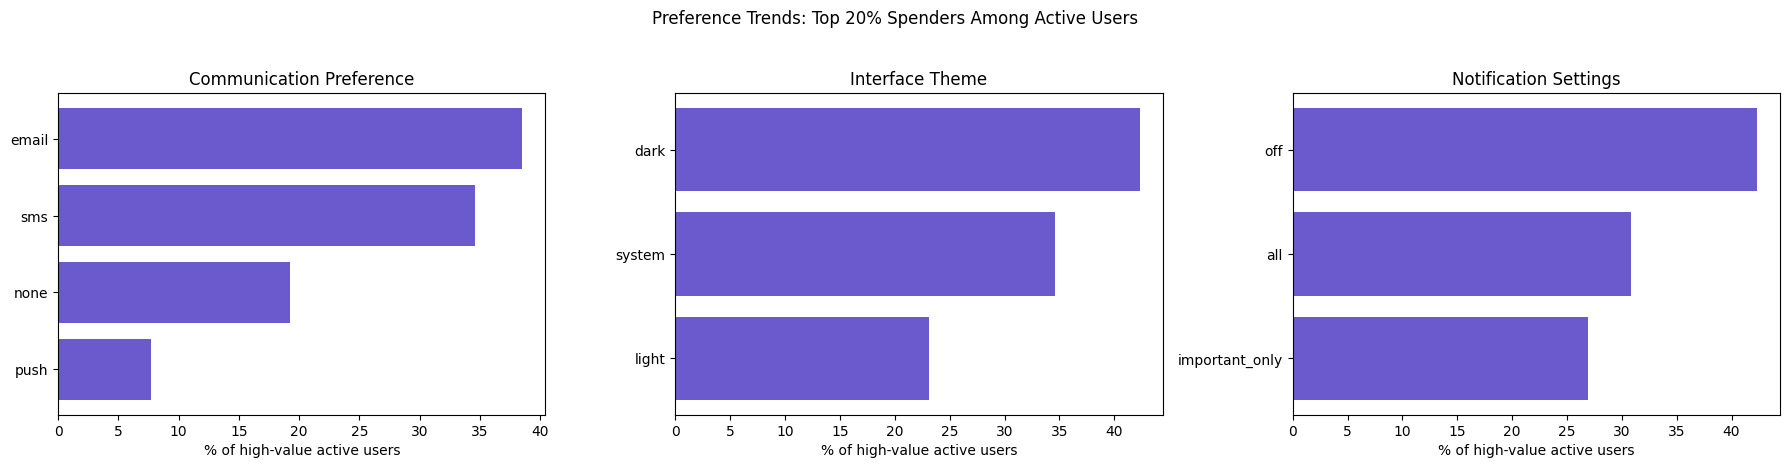

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (pref, grp) in zip(axes, trends.groupby('preference')):
    ax.barh(grp['choice'], grp['pct_of_high_value'], color='slateblue')
    ax.set_title(pref.replace('_', ' ').title())
    ax.set_xlabel('% of high-value active users')
    ax.invert_yaxis()
plt.suptitle('Preference Trends: Top 20% Spenders Among Active Users', y=1.03)
plt.tight_layout(); plt.show()

In [8]:
# Indexes that support the filters, joins and window functions (suggested by the AI)
conn.executescript('''
CREATE INDEX IF NOT EXISTS idx_activity_login ON user_activity(last_login_date, user_id);
CREATE INDEX IF NOT EXISTS idx_tx_user_date   ON transactions(user_id, transaction_date, amount);
CREATE INDEX IF NOT EXISTS idx_prefs_user     ON user_preferences(user_id);
''')
for row in conn.execute("EXPLAIN QUERY PLAN " + segment_sql, params).fetchall()[:8]:
    print(row[-1])

CO-ROUTINE (subquery-9)
CO-ROUTINE prefs
COMPOUND QUERY
LEFT-MOST SUBQUERY
MATERIALIZE ranked
CO-ROUTINE (subquery-10)
MATERIALIZE user_spend
SEARCH user_activity USING INDEX idx_activity_login (last_login_date>? AND last_login_date<?)


## Comparison summary

| | Vague prompt | Detailed prompt |
|---|---|---|
| Percentile | `PERCENTILE_CONT` (PostgreSQL only), over **all** users | `NTILE(5)` window function over **active** users only |
| Date filtering | `CURRENT_DATE - INTERVAL` (not portable, not reproducible) | `date(:as_of, '-30 days')` with a parameter; 12-month spend window |
| Structure / optimization | one query with a subquery in HAVING, grouped by preference columns | step-by-step CTEs, LEFT JOIN for $0 spenders, window function for %, covering indexes |
| Result | **failed** to run in SQLite | ran, and verified against pandas |